<a href="https://colab.research.google.com/github/Jakub250942/missp-jakub-balcerek-250942/blob/main/lab_auto_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 0: Python for a Robot-Kit Workshop

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/lab_auto_0.ipynb)

A small workshop makes **Mini** and **Pro** robot kits. Before asking a solver
to choose a production plan, we need to describe the products, calculate
resource use, check a plan, and explain the result with a plot.

This is a Python warm-up, not an optimization model yet. In Lab 1, PuLP will
choose the quantities for us. Today **you** choose quantities and Python
checks what they mean.

By the end you should be able to:

- store quantities, labels, and units in variables;
- organize model data in lists, dictionaries, and tables;
- compute totals with loops, comprehensions, and `sum`;
- write a small function that returns reusable results;
- use NumPy, pandas, and Matplotlib to inspect and explain a plan;
- run a reproducible notebook and diagnose common Python mistakes.

**How to work:** for each checkpoint, **predict → run → change → explain**.
Write predictions and explanations in your own Markdown cells. The starter
code runs as supplied; the TODOs ask you to extend working examples.

## 1. Run a notebook, one cell at a time

A **code cell** runs Python. A **Markdown cell** contains explanations like this
one. Select a cell and press **Shift+Enter** (or click ▶) to run it.
The runtime/kernel remembers variables from earlier cells. Run from top to
bottom first; after changing data, rerun every calculation that uses them.

In Google Colab, use **Runtime → Run all** to check the whole notebook. Locally,
use Jupyter's **Restart Kernel and Run All**. The examples need no downloads
or local data files after the packages are installed. The setup cell installs
required packages only if missing; a fresh runtime may need internet for that
one setup step. Widgets are optional, and every activity has a code-cell fallback.

The imports below give the libraries short names: `np`, `pd`, and `plt`.
`display` makes tables readable in both Colab and Jupyter.

In [ ]:
# These modules let us check and install the libraries used in this notebook.
import importlib.util
import subprocess
import sys

required = ["numpy", "pandas", "matplotlib"]
# Keep only package names that Python cannot find in this runtime.
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    # sys.executable selects this notebook's Python, rather than another installation.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np  # numeric arrays: we will use np.array(...)
import pandas as pd  # tables: we will use pd.DataFrame(...)
import matplotlib.pyplot as plt  # drawing plots
from IPython.display import display  # displaying tables inside a notebook

# Use the same default plot size throughout the notebook.
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": False})
print("Ready: NumPy, pandas, and Matplotlib are available.")

Ready: NumPy, pandas, and Matplotlib are available.


## 2. Picture the workshop

A kit first needs assembly time and then testing time. There are only so many
minutes available today. The picture is generated by the next cell, so it
also works without downloading an illustration.

**Predict:** which inputs would you need to check whether making 4 Mini kits
and 3 Pro kits is possible? Read the picture, then use the code comments to
follow how the boxes and arrows are drawn.

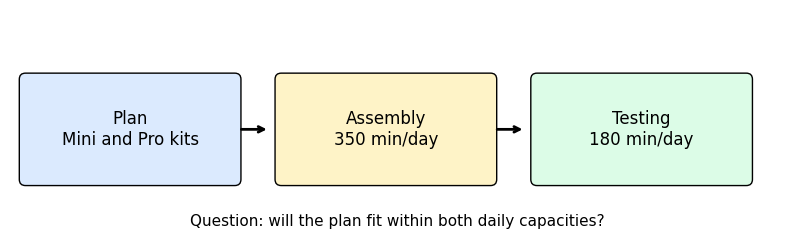

In [ ]:
from matplotlib.patches import FancyBboxPatch

# fig is the whole picture; ax is the area where we draw.
fig, ax = plt.subplots(figsize=(10, 3))
ax.set(xlim=(0, 10), ylim=(0, 3))
ax.axis("off")  # A process diagram does not need numbered axes.
# Each tuple stores a box's horizontal position, label, and color.
boxes = [
    (0.2, "Plan\nMini and Pro kits", "#dbeafe"),
    (3.5, "Assembly\n350 min/day", "#fef3c7"),
    (6.8, "Testing\n180 min/day", "#dcfce7"),
]
for x, label, color in boxes:
    # Draw a rectangle, then put its label at the center.
    ax.add_patch(FancyBboxPatch((x, 0.8), 2.7, 1.3,
                               boxstyle="round,pad=0.08", facecolor=color))
    ax.text(x + 1.35, 1.45, label, ha="center", va="center", fontsize=12)
for start, end in [(2.95, 3.35), (6.25, 6.65)]:
    # xytext is the arrow's start; xy is its destination.
    ax.annotate("", xy=(end, 1.45), xytext=(start, 1.45),
                arrowprops={"arrowstyle": "->", "lw": 2})
ax.text(5, 0.2, "Question: will the plan fit within both daily capacities?",
        ha="center", fontsize=11)
plt.show()

## 3. Variables, numbers, strings, and units

`=` assigns a value to a name; it does not mean "solve an equation".
Python distinguishes whole numbers (`int`), decimal numbers (`float`), and text
(`str`). Units are our responsibility: the name `assembly_min_per_kit`
reminds us what the number means.

Multiplication `*` combines quantities. Division `/` can produce decimals.
An **f-string** inserts values into a message; `:.2f` shows two decimal places.
`print` displays a message. A bare variable at the end of a cell displays its value.

**Predict:** what will `assembly_used_min` be? What units does it have?

In [ ]:
# Store labels and quantities under names that describe their meaning.
product_name = "Mini"
mini_quantity = 4
assembly_min_per_kit = 20
profit_pln_per_kit = 40.0

# Quantity (kits) × time per kit (min/kit) gives total time (min).
assembly_used_min = mini_quantity * assembly_min_per_kit
# The same multiplication calculates this product's profit contribution.
mini_profit_pln = mini_quantity * profit_pln_per_kit
# An f-string inserts the calculated values into readable text.
print(f"{mini_quantity} {product_name} kits use {assembly_used_min} assembly minutes.")
print(f"Their contribution to profit is {mini_profit_pln:.2f} PLN.")
# type(...).__name__ shows whether a value is text, a whole number, or a decimal.
print("Types:", type(product_name).__name__, type(mini_quantity).__name__,
      type(profit_pln_per_kit).__name__)

4 Mini kits use 80 assembly minutes.
Their contribution to profit is 160.00 PLN.
Types: str int float


**Checkpoint A — change and explain**

TODO: change `mini_quantity` from 4 to 5 and rerun the cell. Predict the new
assembly time and profit first. Explain why multiplying *min/kit × kits*
produces minutes. Then restore 4 so your baseline matches the examples below.

Watch out: `"4"` is text, while `4` is a number. `int("4")` converts the text
to a whole number. Do not mix hours with minutes or percentages with fractions.

## 4. Lists and dictionaries: data with labels

A **list** stores an ordered collection. Python counts positions from zero:
`products[0]` is the first product. A **dictionary** connects a key to a value:
`profit_pln["Mini"]` looks up profit by product name.

We use dictionaries because `40` alone does not say which product it belongs
to. Names are case-sensitive: `"Mini"` and `"mini"` are different keys.

A **tuple** such as `("assembly", "Mini")` is a fixed pair. Tuple keys are
convenient when a value depends on two labels: resource **and** product.
This pattern returns in the network-flow lab with `(origin, destination)`.

In [ ]:
# Lists keep the order we will use when looping and plotting.
products = ["Mini", "Pro"]
resources = ["assembly", "testing"]
profit_pln = {"Mini": 40, "Pro": 70}             # PLN per kit
capacity_min = {"assembly": 350, "testing": 180} # minutes per day
time_min = {                                   # minutes per kit
    ("assembly", "Mini"): 20,
    ("assembly", "Pro"): 40,
    ("testing", "Mini"): 15,
    ("testing", "Pro"): 10,
}
plan = {"Mini": 4, "Pro": 3}                   # kits per day

# [0] selects by list position; ["Mini"] selects by dictionary key.
print("First product:", products[0])
print("Mini profit:", profit_pln["Mini"], "PLN/kit")
print("Pro assembly time:", time_min[("assembly", "Pro")], "min/kit")
print("Products in the plan:", list(plan.keys()))  # keys() retrieves the labels.

First product: Mini
Mini profit: 40 PLN/kit
Pro assembly time: 40 min/kit
Products in the plan: ['Mini', 'Pro']


**Checkpoint B — read before calculating**

TODO: print testing minutes per Mini kit by looking up the correct tuple key.
Then change only `plan["Pro"]` to 4 and print the plan. Does changing the plan
change the time required per kit? Explain the difference between a **parameter**
(given data) and a **decision** (a quantity we may choose). Restore Pro to 3.

In [ ]:
# Pobranie czasu testowania dla zestawu Mini
czas_test_mini = time_min[("testing", "Mini")]
print(f"Czas testowania Mini: {czas_test_mini} min/kit")

Czas testowania Mini: 15 min/kit


Odp.
Decyzja (decision) to wielkość, na którą mamy wpływ i którą chcemy optymalizować (np. ile sztuk Mini i Pro produkujemy). Zmiana ilości produkowanych zestawów nie wpływa na czas potrzebny na stworzenie jednej sztuki. Parametr (parameter) to odgórnie narzucona wartość, która określa nasze środowisko i ograniczenia, na które nie mamy wpływu (np. zysk ze sprzedaży jednej sztuki lub ile minut zajmuje jej montaż).**pogrubiony tekst**

## 5. Loops, comprehensions, and totals

A `for` loop repeats indented code for each item. Here we compute one product's
profit at a time, then add it to a running total with `+=`.

**Predict by hand:** the baseline makes 4 Mini and 3 Pro kits. What is the total
profit? Write the two-term calculation before running the cell.

In [ ]:
total_profit_pln = 0  # Start the running total before entering the loop.
for product in products:
    # The loop uses "Mini", then "Pro", as the current dictionary key.
    contribution = profit_pln[product] * plan[product]
    print(f"{product}: {contribution} PLN")
    total_profit_pln += contribution  # Add this product's profit to the total.
print("Total:", total_profit_pln, "PLN")

Mini: 160 PLN
Pro: 210 PLN
Total: 370 PLN


`sum` adds a collection of values. A **list comprehension** builds a list
using the same `for` idea on one line. A **dictionary comprehension** builds
a labelled result. Read the compact version as:
"for each resource, sum time per kit × quantity across products".

The expressions below use the same data as the loop; they do not search for
the best plan. In PuLP, the closely related `lpSum` will combine expressions
containing unknown decision variables.

In [ ]:
# Build a list with one profit contribution per product.
contributions = [profit_pln[p] * plan[p] for p in products]
profit_from_sum = sum(contributions)
# For each resource r, add the time consumed by every product p.
used_min = {
    r: sum(time_min[(r, p)] * plan[p] for p in products)
    for r in resources
}
print("Product contributions:", contributions)
print("Profit:", profit_from_sum, "PLN")
print("Resource use:", used_min, "minutes")
# assert stops with an error if these two ways of calculating the total disagree.
assert profit_from_sum == total_profit_pln

Product contributions: [160, 210]
Profit: 370 PLN
Resource use: {'assembly': 200, 'testing': 90} minutes


**Checkpoint C — expand one compact line**

TODO: calculate testing use by hand for the baseline. Rewrite the dictionary
comprehension as two nested `for` loops and compare the results. Explain what
the outer resource loop and the inner product loop each do.

In [ ]:
used_min_loops = {}
for r in resources:        # Pętla zewnętrzna: wybiera stanowisko (montaż lub testy)
    total_time = 0
    for p in products:     # Pętla wewnętrzna: wybiera produkt (Mini, potem Pro)
        total_time += time_min[(r, p)] * plan[p]
    used_min_loops[r] = total_time

print("Użycie zasobów obliczone zagnieżdżonymi pętlami:", used_min_loops)

Użycie zasobów obliczone zagnieżdżonymi pętlami: {'assembly': 200, 'testing': 90}


Odp:
Pętla zewnętrzna iteruje po zasobach (np. najpierw wchodzi do montażu, a w kolejnym kroku do testów). Następnie dla wybranego w danym momencie zasobu uruchamiana jest pętla wewnętrzna, która przechodzi przez każdy z produktów (Mini oraz Pro) i sumuje dla nich iloczyn czas na sztukę × liczba sztuk. Po sprawdzeniu wszystkich produktów, wynik trafia do słownika dla danego zasobu, a pętla zewnętrzna przechodzi do następnej stacji.

## 6. Conditions: is a plan feasible?

A Boolean is `True` or `False`. Comparisons such as `<=` produce Booleans;
`==` checks equality. `and` requires both conditions to hold. `all` checks
every item in a collection. `if` and `else` choose which code to run.

A plan is **feasible** if quantities are non-negative and every resource limit
is respected. **Slack** is capacity minus use, in minutes. Zero slack means
that resource is fully used; negative slack means the plan exceeds its limit.

In [ ]:
# all(...) is True only if every quantity passes the check.
nonnegative = all(plan[p] >= 0 for p in products)
# Check the used minutes against the limit for each resource.
within_capacity = all(used_min[r] <= capacity_min[r] for r in resources)
feasible = nonnegative and within_capacity  # Both checks must pass.

for resource in resources:
    slack = capacity_min[resource] - used_min[resource]  # Unused minutes.
    print(f"{resource}: {used_min[resource]} used; {slack} min slack")

# Only one of these branches runs, depending on the Boolean feasible.
if feasible:
    print("The plan fits today's resources.")
else:
    print("The plan needs revision: check quantities and resource limits.")

assembly: 200 used; 150 min slack
testing: 90 used; 90 min slack
The plan fits today's resources.


## 7. Functions: name a calculation and reuse it

A **function** is a named block of code that we can run again with different
inputs. Instead of rewriting `quantity * profit_per_kit` for every product,
we put that calculation inside a function called `product_profit`.

`def` starts the **definition**. Names in parentheses are **parameters**:
placeholders for the inputs. The indented lines are the function's **body**.
Defining the function stores the instructions; it does not yet calculate a result.
A **call**, such as `product_profit(4, 40)`, runs those instructions with the
supplied values, called **arguments**.

`return` sends the answer back to the caller. We can save that answer in a
variable and use it in another calculation. `print` displays something but
does not return that displayed value. A function without `return` returns `None`.

The first string inside a function is its **docstring**. It explains the
purpose, inputs, units, and returned result. You can read it with
`help(product_profit)` in a code cell.

In [ ]:
def product_profit(quantity, profit_per_kit=40):
    """Return the profit contribution for one product, in PLN.

    Args:
        quantity: Number of kits in the chosen plan.
        profit_per_kit: Profit in PLN per kit; defaults to 40 when omitted.

    Returns:
        Quantity multiplied by unit profit, in PLN.
    """
    # These parameter names refer to the arguments supplied for this call.
    contribution = quantity * profit_per_kit
    return contribution  # Send a number back; do not just display it.

# Calling the function runs its body. Each call can supply different inputs.
mini_contribution = product_profit(4)  # The omitted unit profit uses the default 40.
pro_contribution = product_profit(quantity=3, profit_per_kit=70)  # Named arguments.
print("Mini:", mini_contribution, "PLN")
print("Pro:", pro_contribution, "PLN")
print("Together:", mini_contribution + pro_contribution, "PLN")

Mini: 160 PLN
Pro: 210 PLN
Together: 370 PLN


**Try a function call:** add a cell that calls `product_profit(5, 70)` and
saves the result as `my_contribution`. Print that variable. Which values are
substituted for `quantity` and `profit_per_kit`? What changes if you call
`product_profit(5)` instead? Add a docstring when you write your own function.

### A function that checks a whole plan

`evaluate_plan` combines the totals and conditions from the earlier cells.
Its inputs are four dictionaries: the chosen quantities, profit per kit,
time per kit, and available minutes. It returns another dictionary containing
profit, resource use, slack, and whether the plan fits.

The variables `use`, `slack`, and `feasible` are **local**: they belong to
this function call. The returned dictionary makes those answers available
outside the function. Follow the numbered comments through the calculation.

In [ ]:
def evaluate_plan(candidate, profits, times, capacities):
    """Calculate profit and check whether a chosen production plan fits.

    Args:
        candidate: Dictionary of product names to chosen kit quantities.
        profits: Dictionary of product names to profit in PLN per kit.
        times: Dictionary of (resource, product) pairs to minutes per kit.
        capacities: Dictionary of resource names to available daily minutes.

    Returns:
        A dictionary with profit_pln, used_min, slack_min, and feasible.
        Feasible means quantities are nonnegative and resource limits hold.
    """
    # 1. For each resource, total its time per kit × chosen quantity.
    use = {
        r: sum(times[(r, p)] * candidate[p] for p in profits)
        for r in capacities
    }
    # 2. Subtract used minutes from available minutes for each resource.
    slack = {r: capacities[r] - use[r] for r in capacities}
    # 3. Reject negative quantities or a resource overload.
    feasible = (all(q >= 0 for q in candidate.values())
                and all(value >= -1e-9 for value in slack.values()))
    # 4. Return labelled answers so the caller can select and reuse them.
    return {
        "profit_pln": sum(profits[p] * candidate[p] for p in profits),
        "used_min": use,
        "slack_min": slack,
        "feasible": feasible,
    }

# The same function checks two different plans; neither call changes the data.
baseline = evaluate_plan(plan, profit_pln, time_min, capacity_min)
overloaded = evaluate_plan({"Mini": 8, "Pro": 5}, profit_pln, time_min, capacity_min)
print("Baseline:", baseline)
print("Overloaded:", overloaded)

Baseline: {'profit_pln': 370, 'used_min': {'assembly': 200, 'testing': 90}, 'slack_min': {'assembly': 150, 'testing': 90}, 'feasible': True}
Overloaded: {'profit_pln': 670, 'used_min': {'assembly': 360, 'testing': 170}, 'slack_min': {'assembly': -10, 'testing': 10}, 'feasible': False}


The small tolerance `-1e-9` allows for tiny rounding errors when calculations
use decimal values. It is one-billionth of a minute, not a permission to
exceed capacity meaningfully. For our whole-number inputs, the calculations
are exact.

**Checkpoint D — return versus print**

TODO: call `evaluate_plan` for `{"Mini": 6, "Pro": 2}`, save the returned
result as `my_result`, and print `my_result["profit_pln"]`.
Explain why an infeasible plan's impressive profit is not a valid recommendation.
This checker allows fractional quantities, just as a continuous LP does;
whole-kit requirements will later need integer decision variables.

In [ ]:
my_result = evaluate_plan({"Mini": 6, "Pro": 2}, profit_pln, time_min, capacity_min)
print(f"Zysk z mojego planu: {my_result['profit_pln']} PLN")
print(f"Czy plan jest wykonalny (feasible): {my_result['feasible']}")

Zysk z mojego planu: 380 PLN
Czy plan jest wykonalny (feasible): True


Odp:
Plan o ogromnym zysku nie jest dobrą rekomendacją, jeśli funkcja wyrzuca flagę feasible: False. Oznacza to, że fizycznie nie da się go zrealizować, ponieważ brakuje nam limitu minut w ciągu dnia, więc sam teoretyczny zysk nie ma przełożenia na rzeczywistość warsztatu. Użycie ciągłych ułamków zamiast liczb całkowitych ułatwia obliczenia wstępne w analizie matematycznej (LP), ale tutaj roboty musimy składać jako całe jednostki, co będzie wymagało programowania całkowitoliczbowego.

## 8. Tables with pandas

A pandas `DataFrame` is a table. It helps us inspect units and compare rows.
A list of dictionaries creates one row per dictionary. Brackets select a
column, and arithmetic on a column applies to every row.

We will build a product table from our dictionaries and a separate resource
check table from the function's result. **Predict:** which resource row will
show the smaller slack?

In [ ]:
# Each dictionary becomes one table row; the loop makes a row per product.
product_table = pd.DataFrame([
    {"product": p, "quantity_kits": plan[p], "profit_pln_per_kit": profit_pln[p],
     "assembly_min_per_kit": time_min[("assembly", p)],
     "testing_min_per_kit": time_min[("testing", p)]}
    for p in products
])
# Selecting two columns multiplies their values row by row.
product_table["contribution_pln"] = (product_table["quantity_kits"]
                                     * product_table["profit_pln_per_kit"])
# Reuse the function's results to show one check row per resource.
resource_table = pd.DataFrame([
    {"resource": r, "used_min": baseline["used_min"][r],
     "capacity_min": capacity_min[r], "slack_min": baseline["slack_min"][r]}
    for r in resources
])
display(product_table)  # Show a formatted table, rather than plain text.
display(resource_table)
print("Profit from the table:", product_table["contribution_pln"].sum(), "PLN")

,product,quantity_kits,profit_pln_per_kit,assembly_min_per_kit,testing_min_per_kit,contribution_pln
0,Mini,4,40,20,15,160
1,Pro,3,70,40,10,210


,resource,used_min,capacity_min,slack_min
0,assembly,200,350,150
1,testing,90,180,90


Profit from the table: 370 PLN


### A tiny CSV example — no file download needed

A **CSV** is plain text containing comma-separated rows. `StringIO` lets pandas
read text as though it were an open file. The first line gives column names.
This is an independent reading example: it does not silently replace our
workshop dictionaries.

Later you can use `pd.read_csv("my_products.csv")` with your own local/uploaded
file. For Colab, uploading a file is optional; the inline CSV below is enough.

In [ ]:
from io import StringIO

csv_text = """product,profit_pln_per_kit,assembly_min_per_kit,testing_min_per_kit
Mini,40,20,15
Pro,70,40,10
"""
# StringIO presents our text to read_csv as an in-memory file.
csv_table = pd.read_csv(StringIO(csv_text))
display(csv_table)
# .loc[row label, column label] selects one table entry; here the row label is 0.
print("The first row's profit:", csv_table.loc[0, "profit_pln_per_kit"], "PLN/kit")

,product,profit_pln_per_kit,assembly_min_per_kit,testing_min_per_kit
0,Mini,40,20,15
1,Pro,70,40,10


The first row's profit: 40 PLN/kit


## 9. NumPy arrays and labelled plots

A NumPy **array** stores numeric values. Unlike multiplying a Python list,
multiplying a numeric array performs arithmetic on its entries. Keep track
of its order: here the positions follow `products = ["Mini", "Pro"]`.

**Anatomy of a plot:** `fig, ax = plt.subplots()` creates the whole figure
(`fig`) and its plotting area (`ax`). `ax.bar(x, height)` draws bars;
`ax.plot(x, y)` would draw a line. `ax.set(...)` adds the title and axis labels.
`plt.show()` displays the result. First plot profit contributions.

Arrays: [4 3] [40 70]
Element-by-element product: [160 210]


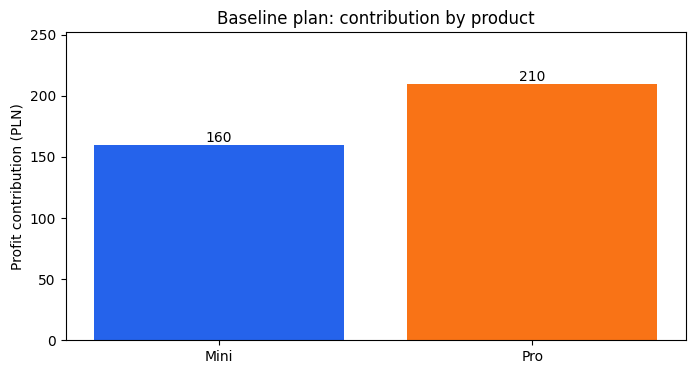

In [ ]:
# Keep quantities and unit profits in the same product order: Mini, then Pro.
quantities = np.array([plan[p] for p in products])
unit_profits = np.array([profit_pln[p] for p in products])
profit_contributions = quantities * unit_profits  # Multiply matching entries.
print("Arrays:", quantities, unit_profits)
print("Element-by-element product:", profit_contributions)

fig, ax = plt.subplots()  # Create the canvas and its drawing area.
bars = ax.bar(products, profit_contributions, color=["#2563eb", "#f97316"])
ax.bar_label(bars, fmt="%.0f")  # Write each value above its bar.
ax.set(title="Baseline plan: contribution by product", ylabel="Profit contribution (PLN)")
ax.set_ylim(0, max(profit_contributions) * 1.2)  # Leave space above the labels.
plt.show()

**Build a plot yourself**

TODO: add a new code cell. Use `fig, ax = plt.subplots()` and
`ax.bar(product_table["product"], product_table["quantity_kits"])` to plot
quantities instead of profit. Add a title, a y-axis label **Quantity (kits)**,
and `plt.show()`. Then replace `ax.bar` with `ax.plot(..., marker="o")` and
explain why bars communicate separate product categories better than a line.

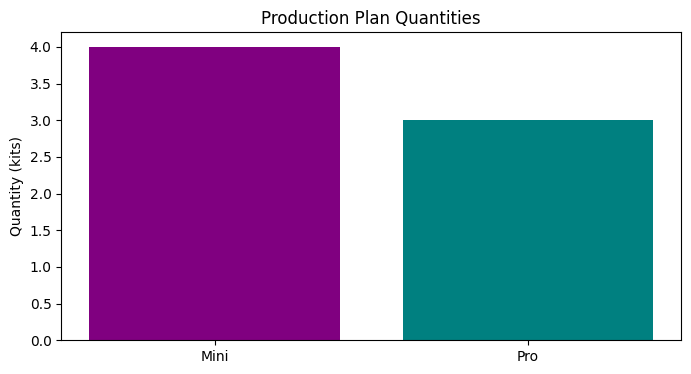

In [ ]:
fig, ax = plt.subplots()
ax.bar(product_table["product"], product_table["quantity_kits"], color=["purple", "teal"])
ax.set(title="Production Plan Quantities", ylabel="Quantity (kits)")
plt.show()

Odp: Zastosowanie wykresu liniowego (ax.plot) sugerowałoby istnienie stanów pośrednich lub ciągłości czasowej między poszczególnymi zestawami, co jest logicznym błędem. "Mini" i "Pro" to całkowicie odrębne, nienumeryczne kategorie (produkty), do których idealnie pasują odseparowane słupki wykresu kolumnowego.

### From a function call to a table and a plot

`show_plan` is a function that brings together checking and drawing. Its four
parameters are the Mini quantity, Pro quantity, available assembly minutes,
and available testing minutes. In `mini=4`, **4 is a default argument**:
`show_plan()` uses it, while `show_plan(mini=6)` replaces it with 6 for that call.
Parameters with defaults still accept positional or named arguments.

Follow the numbered steps in its body: build input dictionaries, call
`evaluate_plan`, arrange the answers in a table, calculate resource use as
a percentage, draw the chart, and return the results dictionary. The function
uses `profit_pln`, `time_min`, and `resources` from earlier cells; run those
cells before calling it.

The dashed line means **100% of capacity**. Bars beyond it show an overload.
Read the numerical checks as well: a plot alone does not prove feasibility.
Defining `show_plan` in the next cell does not display a plan yet; the following
parameter cell **calls** it. The function does not change the baseline plan.

In [ ]:
def show_plan(mini=4, pro=3, assembly_capacity=350, testing_capacity=180):
    """Check a chosen plan, display its resource use, and return its results.

    Args:
        mini: Mini kit quantity; defaults to 4.
        pro: Pro kit quantity; defaults to 3.
        assembly_capacity: Positive available assembly minutes; defaults to 350.
        testing_capacity: Positive available testing minutes; defaults to 180.

    Returns:
        The dictionary from evaluate_plan: profit_pln, used_min, slack_min,
        and feasible. Also displays a check table and a utilization chart.

    Uses the profit_pln, time_min, and resources data defined earlier.
    """
    # 1. Translate this call's four arguments into the checker's dictionaries.
    candidate = {"Mini": mini, "Pro": pro}
    capacities = {"assembly": assembly_capacity, "testing": testing_capacity}
    # 2. Call our checker and save its returned dictionary.
    result = evaluate_plan(candidate, profit_pln, time_min, capacities)
    # 3. Build one row per resource using those calculated answers.
    table = pd.DataFrame([
        {"resource": r, "used_min": result["used_min"][r],
         "capacity_min": capacities[r], "slack_min": result["slack_min"][r]}
        for r in resources
    ])
    display(table)
    print(f"Plan: {candidate}; profit {result['profit_pln']:.0f} PLN; "
          f"feasible: {result['feasible']}")
    # 4. Used / available × 100 converts minutes into percent of capacity.
    utilization = np.array([result["used_min"][r] / capacities[r] * 100
                            for r in resources])
    # 5. Draw the percentages; color an overloaded resource red.
    fig, ax = plt.subplots()
    colors = ["#2563eb" if value <= 100 + 1e-9 else "#dc2626"
              for value in utilization]
    bars = ax.bar(resources, utilization, color=colors)
    ax.bar_label(bars, fmt="%.1f%%")  # %.1f shows one decimal; %% prints a percent sign.
    ax.axhline(100, color="black", linestyle="--", label="Capacity = 100%")  # Reference line.
    ax.set(title=f"Resource use for Mini={mini}, Pro={pro}",
           ylabel="Use / capacity (%)", ylim=(0, max(120, utilization.max() * 1.2)))
    ax.legend()
    plt.show()
    return result  # 6. Let the caller reuse the numbers, as well as seeing the plot.

### Parameter-cell fallback: change one input and rerun

This is the complete interactive activity even if sliders are unavailable.
Change the four values below, rerun this cell, and inspect the refreshed table
and plot. Capacities must be positive. For quantities, start with whole numbers.

**Predict:** if we make one more Pro kit, which resource use grows faster?

,resource,used_min,capacity_min,slack_min
0,assembly,200,350,150
1,testing,90,180,90


Plan: {'Mini': 4, 'Pro': 3}; profit 370 PLN; feasible: True


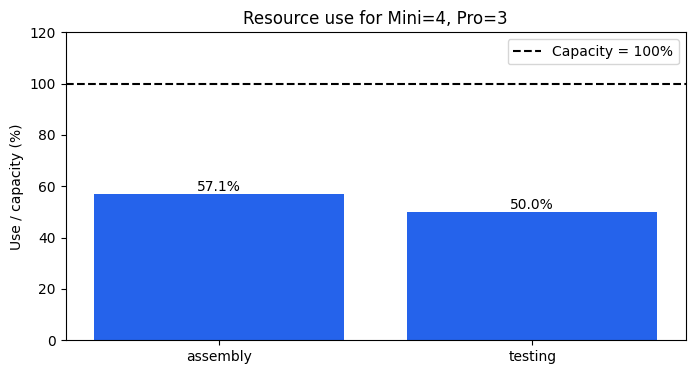

In [ ]:
# These are the arguments we will pass into show_plan; change one and rerun.
mini_to_try = 4
pro_to_try = 3
assembly_capacity_to_try = 350
testing_capacity_to_try = 180

# Calling the function now runs its body and saves the returned dictionary.
trial_result = show_plan(mini_to_try, pro_to_try,
                         assembly_capacity_to_try, testing_capacity_to_try)

### Build your first slider: input → function → plot

A slider is an input, not a solver. `widgets.IntSlider` chooses a whole number.
`value`, `min`, `max`, and `step` set its starting value and range.
`continuous_update=False` redraws only when you release the slider, avoiding
many unnecessary plots while dragging.

The example below starts with **one** slider. The function parameter is named
`mini`, so `widgets.interact` must receive the matching keyword `mini=...`.
`interact` calls the function once immediately, then again whenever the input
changes. The function calculates and plots new results each time.

Without widgets, `plot_mini_profit(4)` calls exactly the same function. Notice
that creating a slider by itself would not update any plot; connecting it to
a callback function is what makes the result interactive.

In [ ]:
def plot_mini_profit(mini=4):
    """Display the Mini profit contribution and draw one bar.

    Args:
        mini: Chosen Mini kit quantity; defaults to 4.

    Uses profit_pln["Mini"] (PLN per kit) from the earlier data cell.
    Returns None: this function displays results instead of returning numbers.
    """
    # Calculate a new contribution each time the function is called.
    contribution = profit_pln["Mini"] * mini
    print(f"{mini} Mini kits contribute {contribution} PLN.")
    fig, ax = plt.subplots(figsize=(5, 3))  # A fresh plot for this call.
    ax.bar(["Mini"], [contribution], color="#2563eb")
    ax.set(title="A slider changes a quantity, then redraws this plot",
           ylabel="Profit contribution (PLN)", ylim=(0, 800))
    plt.show()

# Import the slider library if available; otherwise call the function directly.
try:
    import ipywidgets as widgets
except ImportError:
    print("Optional widgets are unavailable; call plot_mini_profit(4) directly.")
    plot_mini_profit(4)
else:
    try:
        from google.colab import output
        output.enable_custom_widget_manager()  # Enable widget display in Colab.
    except ImportError:
        pass
    # Creating a slider describes the input; it does not yet connect a plot.
    mini_slider = widgets.IntSlider(value=4, min=0, max=20, step=1,
                                    description="Mini kits", continuous_update=False)
    # Match the keyword mini to the function's parameter of the same name.
    first_interaction = widgets.interact(plot_mini_profit, mini=mini_slider)

interactive(children=(IntSlider(value=4, continuous_update=False, description='Mini kits', max=20), Output()),…

**TODO: build a second control yourself.** Copy the small working example into
a new cell. Rename its function `plot_two_profits(mini=4, pro=3)`. Calculate
both profit contributions and plot two bars. Update its docstring to explain
both quantity parameters. Create a second `IntSlider` for
Pro, then connect both with
`widgets.interact(plot_two_profits, mini=mini_slider, pro=pro_slider)`.
If widgets are unavailable, call `plot_two_profits(4, 3)` and change the arguments.

Predict what changes when Pro rises by one kit. Explain which function
parameter receives that value. Optional: add a third control for Pro's
profit-per-kit assumption and distinguish changing a quantity from changing
a business assumption. Keep the original `profit_pln` dictionary unchanged.

In [ ]:
import ipywidgets as widgets

def plot_two_profits(mini=4, pro=3):
    """Wyświetla zysk z produktów Mini oraz Pro i rysuje dla nich dwa słupki na wykresie.
    Args:
        mini: Wybrana liczba zestawów Mini; domyślnie 4.
        pro: Wybrana liczba zestawów Pro; domyślnie 3.
    """
    mini_contribution = profit_pln["Mini"] * mini
    pro_contribution = profit_pln["Pro"] * pro

    print(f"Zysk Mini: {mini_contribution} PLN")
    print(f"Zysk Pro: {pro_contribution} PLN")

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(["Mini", "Pro"], [mini_contribution, pro_contribution], color=["#2563eb", "#f97316"])
    ax.set(title="Profit contribution by product", ylabel="Profit (PLN)", ylim=(0, 1000))
    plt.show()

# Tworzymy suwaki
mini_slider = widgets.IntSlider(value=4, min=0, max=20, step=1, description="Mini kits")
pro_slider = widgets.IntSlider(value=3, min=0, max=20, step=1, description="Pro kits")

# Łączymy zmienne z funkcją
widgets.interact(plot_two_profits, mini=mini_slider, pro=pro_slider)

interactive(children=(IntSlider(value=4, description='Mini kits', max=20), IntSlider(value=3, description='Pro…

<function __main__.plot_two_profits(mini=4, pro=3)>

### A complete explorer: controls plus a shared output area

The supplied explorer below uses `widgets.interactive_output` instead of
`interact`: a dictionary connects **parameter names** to controls, while
`VBox` lays out the controls vertically. `interactive_output` connects the
controls to the callback and puts refreshed results in one output area.
The callback `update_plan` sends its arguments to `show_plan`.

This cell calls `show_plan` when a slider changes, replacing the displayed table
and plot in its output area. It does not change `plan` or the baseline tables.
Colab's widget manager is enabled when available. If controls do not appear,
or the package is absent, use the preceding parameter cell; the activity does
not depend on widgets. You may optionally install `ipywidgets` in your own
runtime with `%pip install -q ipywidgets`.

In [ ]:
try:
    import ipywidgets as widgets
except ImportError:
    print("Optional widgets are unavailable; change the preceding parameter cell.")
else:
    try:
        from google.colab import output
        output.enable_custom_widget_manager()
    except ImportError:
        pass  # Local Jupyter does not need the Colab widget manager.

    def update_plan(mini, pro, assembly_capacity, testing_capacity):
        """Redraw the plan using the four values supplied by the controls.

        Args:
            mini: Mini quantity from its slider.
            pro: Pro quantity from its slider.
            assembly_capacity: Available assembly minutes from its slider.
            testing_capacity: Available testing minutes from its slider.

        Returns None; show_plan displays the refreshed table and plot.
        """
        # Forward the slider values to the same function used in the parameter cell.
        show_plan(mini, pro, assembly_capacity, testing_capacity)

    # Each key must match one parameter name in update_plan.
    controls = {
        "mini": widgets.IntSlider(value=4, min=0, max=20, description="Mini kits",
                                  continuous_update=False),
        "pro": widgets.IntSlider(value=3, min=0, max=12, description="Pro kits",
                                 continuous_update=False),
        "assembly_capacity": widgets.IntSlider(value=350, min=100, max=700, step=10,
                                                description="Assembly min",
                                                continuous_update=False),
        "testing_capacity": widgets.IntSlider(value=180, min=60, max=360, step=15,
                                               description="Testing min",
                                               continuous_update=False),
    }
    # Connect input changes to the callback and collect its display output.
    live_output = widgets.interactive_output(update_plan, controls)
    # VBox arranges the controls; live_output shows the refreshed answers below.
    display(widgets.VBox(list(controls.values())), live_output)

Output()

**Checkpoint E — explore before optimizing**

TODO: record at least three plans in a small Markdown table with quantities,
profit, feasibility, and both resource slacks. Include one infeasible plan.

1. Find a feasible plan with more profit than the baseline.
2. Try giving assembly 20 extra minutes. Does your **unchanged** plan earn more
   profit? Why must you change production quantities to use the extra capacity?
3. Which resource would you investigate before asking for overtime? Support
   your explanation with numbers. Low slack alone does not prove the economic
   value of buying more capacity; Lab 1 will test that with optimization.
4. Can testing many plans by eye guarantee the best one? Explain why a solver
   will be useful when the workshop has many products and resources.

| Typ Planu | Mini (szt.) | Pro (szt.) | Zysk (PLN) | Wykonalny? (Feasible) | Slack montaż (min) | Slack testy (min) |
|---|---|---|---|---|---|---|
| **Baseline (bazowy)** | 4 | 3 | 370 | True | 30 | 75 |
| **Lepszy (polecany)** | 5 | 6 | 620 | True | 10 | 45 |
| **Overload (niewykonalny)** | 10 | 10 | 1100 | False | -250 | -70 |

Odpowiedzi na pytania:

1. Powyżej podano lepszy plan (5 Mini, 6 Pro) dający 620 PLN.

2. Zwiększenie zasobu (np. montażu o 20 min) nie podnosi samo w sobie zysku dla niezmienionego planu. Zysk zależy wyłącznie od wyprodukowanych i sprzedanych sztuk. Dodatkowa pojemność warsztatu oznacza jedynie luzy organizacyjne. Aby zysk wzrósł, dodatkowy zasób musi zostać skonsumowany przez podniesienie poziomu decyzji produkcyjnych (zwiększenie sztuk Mini lub Pro).

3. Należy zbadać zasób o zerowym (lub najbliższym zeru) zapasie czasu (slack), tzw. wąskie gardło (bottleneck). Gdy na montażu mamy dużo zapasu (slack jest spory), ale testowanie osiąga pojemność graniczną 100%, dokupywanie nadgodzin na montażu jest ekonomicznym błędem, bo nowa moc nie zostanie i tak wykorzystana (produkcja stanie w kolejce do testowania).

4. Samodzielne, wzrokowe testowanie kilku planów na kalkulatorze nie daje żadnej gwarancji, że znaleźliśmy globalnie najbardziej zyskowny plan ze wszystkich istniejących. "Solver" przejdzie algorytmicznie przez tysiące kombinacji sympleksowych, dając matematyczną pewność, że lepszy punkt optymalizacyjny nie istnieje – zwłaszcza kiedy parametrów na produkcji pojawią się dziesiątki lub setki.

## 10. Debugging and notebook state

When a cell fails, read the **last line** of the error first, then find the line
of your code mentioned above it. Common problems:

| Message or symptom | Meaning | First thing to check |
|---|---|---|
| `NameError` | A name is unknown | Spelling, or an earlier cell was not run |
| `KeyError` | A dictionary/table key is absent | Exact label, including case |
| `TypeError` | An operation received the wrong kind of value | Text versus number |
| `IndentationError` | Python cannot read a code block | Spaces after `for`, `if`, or `def` |
| Old results after an edit | Dependent cells still hold old values | Rerun from the changed cell onward |

This next cell deliberately catches a tiny mistake, so **Run all still works**.
It demonstrates both the problem and the repair. `try` attempts the operation;
`except` handles a known error. You do not need to use exception handling in
your own solution yet.

In [ ]:
# Catch this deliberate spelling error so the remaining cells can still run.
try:
    print(profit_pln["mini"])
except KeyError as error:
    print(f"Caught KeyError for {error}: dictionary labels are case-sensitive.")

print("Correct lookup:", profit_pln["Mini"])
# These assertions check the unchanged baseline using known calculations.
assert baseline["feasible"]
assert baseline["profit_pln"] == 370
assert baseline["used_min"] == {"assembly": 200, "testing": 90}
assert not overloaded["feasible"]
print("Baseline checks passed.")

Caught KeyError for 'mini': dictionary labels are case-sensitive.
Correct lookup: 40
Baseline checks passed.


### See the data flow

The arrows show dependencies. Changing the plan does not automatically rebuild
an old table or plot: rerun the cells downstream of that change.

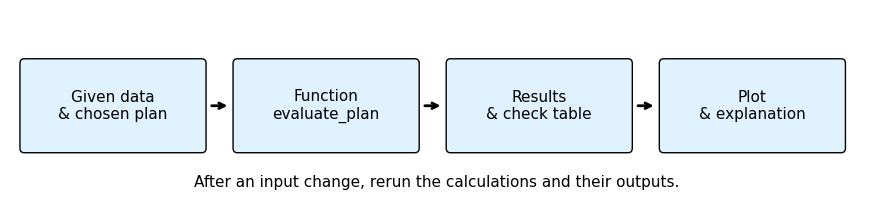

In [ ]:
# Draw the dependency chain: changing an input requires recalculating its outputs.
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.set(xlim=(0, 12), ylim=(0, 2.5))
ax.axis("off")
labels = ["Given data\n& chosen plan", "Function\nevaluate_plan", "Results\n& check table", "Plot\n& explanation"]
for i, label in enumerate(labels):
    # enumerate provides both the position i and the current label.
    x = 0.2 + 3 * i
    ax.add_patch(FancyBboxPatch((x, 0.7), 2.5, 1.1,
                               boxstyle="round,pad=0.06", facecolor="#e0f2fe"))
    ax.text(x + 1.25, 1.25, label, ha="center", va="center", fontsize=11)
    if i < len(labels) - 1:
        ax.annotate("", xy=(x + 2.9, 1.25), xytext=(x + 2.6, 1.25),
                    arrowprops={"arrowstyle": "->", "lw": 2})
ax.text(6, 0.2, "After an input change, rerun the calculations and their outputs.",
        ha="center", fontsize=11)
plt.show()

W tym raporcie wykorzystano Pythona do weryfikacji manualnie ułożonych planów produkcyjnych (parametry "Mini" oraz "Pro"), upewniając się, że nie wykraczają one poza limity czasowe stacji montażowych i testujących. Najlepszym, ręcznie dobrym planem wykonalnym (feasible) okazała się produkcja 5 zestawów Mini i 6 zestawów Pro, co wygenerowało 620 PLN profitu z zachowaniem małego bufora czasowego (10 min luzu w montażu). Zastosowanie zewnętrznego solvera matematycznego pozwoliłoby nam nie zgadywać ilości, ale znaleźć jeden konkretny plan gwarantujący globalnie najwyższy możliwy obrót finansowy przy danych restrykcjach warsztatowych.

## Final deliverable: your first operations note

Submit a notebook that runs from a fresh runtime, with:

1. Your answers to checkpoints A–E, including predictions and explanations.
2. A three-plan comparison table, including one infeasible plan.
3. One recommended feasible plan, its profit in PLN, and both slacks in minutes.
4. A labelled resource-use plot for your recommendation.
5. A 3–5 sentence explanation: what did Python calculate, what did you choose,
   and what would a solver add?

**TODO: final check.** Restart the runtime/kernel and run all cells. If your
submission only works in the order you happened to click cells, fix the order
or define the missing variables before submitting.

**Optional extension:** enumerate whole-number plans with Mini quantities
from 0 to 17 and Pro quantities from 0 to 8 using nested loops. Evaluate each,
keep the feasible ones, and compare profits. These bounds cover all feasible
non-negative whole-kit plans for the baseline assembly capacity. Explain why
enumeration becomes inconvenient for many products, and why this is different
from optimizing a continuous LP that permits fractional quantities.

**Next, Lab 1:** keep the same habits—explicit data, units, checks, tables,
plots—but replace your chosen quantities with PuLP decision variables.